# 06 DERRETIMENTO BASAL LAGRANGIANO NAS PLATAFORMAS DA ASE, ESCALA ÓTIMA DA DIVERGÊNCIA, MANCHAS NEGATIVAS E FATORIAL DE INCERTEZA ESTRUTURAL

Este caderno apresenta a teoria física, a formulação numérica e os resultados do produto de derretimento basal ($m_b$, 2019–2025) sobre as plataformas de gelo do Mar de Amundsen (**Pine Island**, **Thwaites Oriental/TEIS**, **Crosson**, **Dotson** e **Cosgrove**), construído a partir de $4.574$ grânulos ATL06 r007 nas quatro estações austrais (DJF, MAM, JJA, SON):

$$m_b(x, y) = \text{SMB}(x, y) - \frac{DH}{Dt}(x, y) - H(x, y)\left(\nabla\cdot\mathbf{u}(x, y)\right)$$


### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 1 | Conservação de massa Lagrangiana e estado da arte | tabela final de $m_b$ e massa por plataforma | — |
| 2 | Divergência de velocidade com lacunas e escala ótima | derivada gaussiana normalizada vs. diferenças finitas; CV anos pares × ímpares | `thwaites.stats.spatial_cv` |
| 3 | Séries de espessura por efeitos fixos de célula material | painel sintético com cobertura variável; séries reais GEMB × IMAU; CV do interpolador | `thwaites.stats.panel_schur` |
| 4 | Manchas de $m_b < 0$ e velocidade ITS_LIVE × MEaSUREs | colapso com a escala de $\nabla\cdot\mathbf{u}$; recongelamento significativo | `run_blue_spots_ase.py` |
| 5 | Incerteza estrutural fatorial e comparação com a literatura | efeitos por fator; Meng et al. (2025) e Paolo et al. (2023) | `run_factorial_v2_ase.py` |
| 6 | Síntese | — | — |

---

## 1. Fundamentação Física e Comparação com o Estado da Arte (2014–2026)

A literatura de estimativa de derretimento basal por altimetria de satélite evoluiu ao longo de três gerações metodológicas:
1. **Primeira geração (ICESat/CryoSat-2 em grades de $1\text{--}10\text{ km}$; Moholdt et al., 2014; Paolo et al., 2023; Adusumilli et al., 2020):** Estabeleceu que a formulação Lagrangiana reduz a variância espúria de advecção em $\sim 50\%$, mas utilizou um único modelo de firn/SMB, máscaras estáticas de linha de aterramento e propagou apenas erros gaussianos formais;
2. **Segunda geração (DEMs estereofotogramétricos WorldView/REMA e CryoSat-2 *swath*; Shean et al., 2019; Zinck et al., 2023, 2026; Davison et al., 2023; Chartrand et al., 2024; Lowery et al., 2025, 2026):** Demonstrou que canais basais e zonas de cisalhamento concentram taxas extremas de fusão, mas que o desequilíbrio hidrostático por fendas basais (Vaughan et al., 2012) e aterramento transitório produz **faixas alternadas de ganho e perda aparente ($m_b < 0$)** com incerteza pontual de $\pm 8\text{ a }\pm 28\text{ m/ano}$ (Chartrand et al., 2024, Tabela 1);
3. **Comparador direto com ICESat-2 ATL06 na ASE (Meng et al., 2025, *Environ. Res. Lett.*, 20, 084016, período 2019–2023):** Meng et al. (2025) estimaram taxas médias para as plataformas da ASE, porém com cinco limitações estruturais que este trabalho resolve diretamente:
   - *(i)* Usaram um buffer fixo de $2\text{ km}$ na linha de aterramento de 2007–2009 (que inclui gelo em flexão na Dotson/Cosgrove e descarta gelo flutuante na Thwaites/Crosson);
   - *(ii)* Aplicaram um único modelo de firn (IMAU-FDM) e de SMB (RACMO2.3p2), omitindo a incerteza epistêmica entre modelos de firn (que mostramos pesar $3{,}6\text{ m/ano}$ na Pine Island);
   - *(iii)* Declararam apenas incerteza por desvio móvel local ($\pm 1{,}46\text{ m/ano}$ na PIG), $3\times$ menor que a incerteza total quando se incluem firn, agregação e velocidade;
   - *(iv)* Não validaram o produto contra radares de fase *in situ* (ApRES) nem contra radar aerotransportado (MCoRDS);
   - *(v)* Afirmaram coerência das anomalias com o ENSO sem corrigir os graus de liberdade pela forte autocorrelação induzida pelo filtro temporal.

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tab_final = pd.read_csv(DATA_DIR / "tabela_final_basal_ase.csv")
unc_v2 = pd.read_csv(DATA_DIR / "incerteza_estrutural_basal_resumo.csv")
cv_krig = pd.read_csv(DATA_DIR / "cv_interpolacao_basal.csv")
div_diag = pd.read_csv(DATA_DIR / "divergencia_escala_cv.csv")
vel_check = pd.read_csv(DATA_DIR / "velocidade_itslive_vs_measures.csv")
blue_spots = pd.read_csv(DATA_DIR / "blue_spots_resumo_por_unidade.csv")
check_refreeze = pd.read_csv(DATA_DIR / "open_check_8_recongelamento.csv")
ser_h = pd.read_csv(DATA_DIR / "serie_espessura_f090.csv")

tab_final.set_index("unidade").round(2)

,mb_mpa,sigma_estat,sigma_estrutural,sigma_total,fator_velocidade,area_medida_km2,area_inteira_km2,frac_medida,Gt_medido,sigma_Gt_medido,Gt_inteira_min,Gt_inteira_max,sigma_Gt_inteira
unidade,,,,,,,,,,,,,
Pine_Island,17.53,0.48,4.51,4.53,-0.61,3039.00,5232.25,0.58,48.86,12.64,82.80,84.12,21.77
Thwaites_TEIS,6.88,0.40,3.07,3.10,-0.50,764.75,1084.50,0.71,4.82,2.17,6.84,7.83,3.12
Crosson,8.76,0.25,1.19,1.22,-0.11,1950.75,3176.75,0.61,15.66,2.17,25.51,27.48,3.68
Dotson,6.66,0.17,0.74,0.76,0.03,3843.00,5741.25,0.67,23.46,2.67,35.05,43.23,5.72
Cosgrove,0.71,0.09,0.37,0.38,-0.30,2103.75,3041.25,0.69,1.37,0.74,1.97,2.41,1.09
TOTAL (sem TWGT),NaN,NaN,NaN,NaN,NaN,11701.25,18276.00,NaN,94.18,20.40,152.18,165.07,35.38


**Leitura da tabela.**
- **Ordem de grandeza:** a Pine Island derrete ~17,5 m/ano em média; Crosson, Dotson e TEIS, 7–9 m/ano; Cosgrove, menos de 1 m/ano. Em massa, a PIG sozinha responde por ~55% das ~152–165 Gt/ano das cinco plataformas inteiras.
- **Incerteza:** a componente estatística ($\sigma_{\text{estat}}$, ruído do ajuste) é 5–10× menor que a **estrutural** (escolhas metodológicas: firn, agregação, máscara, escala de $\nabla\cdot\mathbf{u}$; Seção 5). Reportar só $\sigma_{\text{estat}}$ subestimaria a incerteza real em até uma ordem de grandeza.
- **Área medida vs. inteira:** o ICESat-2 cobre 58–71% de cada plataforma. A extrapolação para a área inteira é dada como faixa (`Gt_inteira_min`–`Gt_inteira_max`), não como valor único.

---
## 2. Divergência de Velocidade: Derivadas com Lacunas e Escala Ótima

**Fundamentação.** O termo $H(\nabla\cdot\mathbf{u})$ exige derivar mosaicos de velocidade com lacunas (`NaN`) e ruído. Diferenças finitas simples propagam cada `NaN` para os vizinhos e amplificam o ruído. A **convolução normalizada** (Knutsson & Westin, 1993) suaviza apenas sobre os pixels válidos e deriva pela regra do quociente (Caderno 00, docstring de `spatial_cv`). A escala $\sigma$ do kernel controla o compromisso ruído × resolução e é escolhida por validação cruzada entre mosaicos de anos pares e ímpares.

**Aplicação 1.** Campo de velocidade sintético $u(x) = 1500\tanh[(x - 50\text{ km})/20\text{ km}]$ m/ano, com ruído de 30 m/ano, 25% de pixels ausentes e um buraco de 8 km de raio:

,Pixels com valor (%),RMSE de ∂u/∂x (1/ano)
Método,,
Diferenças finitas (np.gradient),54.3828,0.0424
Gaussiana normalizada σ = 0.5 km,93.9219,0.0152
Gaussiana normalizada σ = 1.0 km,96.5312,0.0048
Gaussiana normalizada σ = 2.0 km,96.4023,0.0026
Gaussiana normalizada σ = 4.0 km,96.3477,0.0033


,σ* ótimo (km)
plataforma,
Cosgrove,1.0
Crosson,1.0
Dotson,1.0
Pine_Island,3.0
Thwaites,2.0


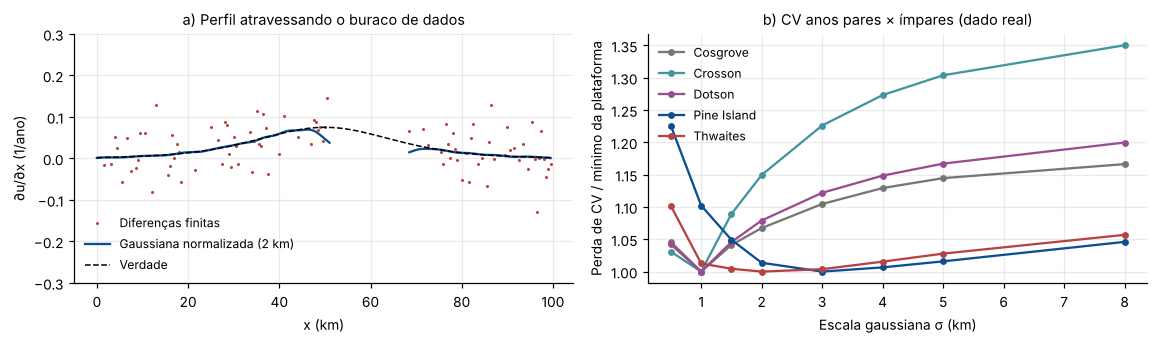

In [3]:
from thwaites.stats import normalized_gaussian_derivative

N, dx = 200, 500.0
xg = np.arange(N) * dx
XG, YG = np.meshgrid(xg, xg)
u_true = 1500 * np.tanh((XG - 50e3) / 20e3)
dudx_true = 1500 / 20e3 / np.cosh((XG - 50e3) / 20e3) ** 2
rng = np.random.default_rng(2)
u_obs = u_true + rng.normal(0, 30, u_true.shape)
lacuna = (rng.random(u_true.shape) < 0.25) | (((XG - 60e3) ** 2 + (YG - 50e3) ** 2) < 8e3 ** 2)
u_obs[lacuna] = np.nan

interior = (slice(20, -20), slice(20, -20))          # exclui bordas do domínio
linhas = []
ingenua = np.gradient(u_obs, dx, axis=1)
linhas.append({"Método": "Diferenças finitas (np.gradient)", "Pixels com valor (%)": 100 * np.isfinite(ingenua[interior]).mean(),
               "RMSE de ∂u/∂x (1/ano)": np.sqrt(np.nanmean((ingenua - dudx_true)[interior] ** 2))})
for s_px in [1, 2, 4, 8]:
    d_norm = normalized_gaussian_derivative(u_obs, s_px, axis=1) / dx
    linhas.append({"Método": f"Gaussiana normalizada σ = {s_px * dx / 1e3:.1f} km",
                   "Pixels com valor (%)": 100 * np.isfinite(d_norm[interior]).mean(),
                   "RMSE de ∂u/∂x (1/ano)": np.sqrt(np.nanmean((d_norm - dudx_true)[interior] ** 2))})
tab_div = pd.DataFrame(linhas).set_index("Método")

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.2))
lin = 100
ax[0].plot(xg / 1e3, ingenua[lin], ".", ms=2, color="#B64342", label="Diferenças finitas")
ax[0].plot(xg / 1e3, normalized_gaussian_derivative(u_obs, 4, axis=1)[lin] / dx, color="#0F4D92", lw=1.5, label="Gaussiana normalizada (2 km)")
ax[0].plot(xg / 1e3, dudx_true[lin], "k--", lw=1, label="Verdade")
ax[0].set_ylim(-0.3, 0.3); ax[0].set_xlabel("x (km)"); ax[0].set_ylabel("∂u/∂x (1/ano)")
ax[0].set_title("a) Perfil atravessando o buraco de dados"); ax[0].legend(frameon=False, fontsize=8)

for plat, g in div_diag.groupby("plataforma"):
    cor = CORES.get(plat if plat != "Thwaites" else "Thwaites_TEIS", "#767676")
    ax[1].plot(g["sigma_km"], g["cv_1pa"] / g["cv_1pa"].min(), "o-", ms=3.5, color=cor, label=plat.replace("_", " "))
ax[1].set_xlabel("Escala gaussiana σ (km)"); ax[1].set_ylabel("Perda de CV / mínimo da plataforma")
ax[1].set_title("b) CV anos pares × ímpares (dado real)"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

escala_otima = pd.read_csv(DATA_DIR / "divergencia_escala_otima.csv").set_index("plataforma")
display(tab_div.round(4))
escala_otima.rename(columns={"sigma_km": "σ* ótimo (km)"})

**Leitura do resultado.**
- **Aplicação 1:** as diferenças finitas perdem quase metade dos pixels (cada `NaN` contamina os vizinhos) e têm erro da ordem do próprio sinal. A convolução normalizada mantém ~96% dos pixels e reduz o erro ~9× com $\sigma = 1$ km e ~16× com $\sigma = 2$ km. Acima de ~2 km o ganho satura, porque o viés de suavização começa a competir com a redução de ruído.
- **Painel (b), dado real:** a perda de CV tem mínimo bem definido em cada plataforma. As rápidas e heterogêneas (PIG, 3 km; Thwaites, 2 km) pedem mais suavização; as lentas (Crosson, Dotson, Cosgrove) preferem 1 km. A escala não é escolhida a olho: ela sai dos dados, e sua sensibilidade entra no fatorial da Seção 5 (`efeito_escala_km`).

---

---
## 3. Séries de Espessura por Efeitos Fixos de Célula Material (GEMB vs. IMAU-FDM) e Seleção de Interpolador para $DH/Dt$

No Passo 5 da cadeia basal (`run_thickness_ase.py`), cada segmento sobre a máscara hidrostática é convertido em espessura equivalente $H = 9{,}336\,(h_{\text{mar}} - \text{FAC})$ usando dois modelos independentes de conteúdo de ar do firn interpolados por triangulação de Delaunay no espaço e linearmente no tempo: **GEMB v1.5** (2018–2025) e **IMAU-FDM v1.2A** (2018–2023,98). A série trimestral $s_k$ ($K = 28$ estações-ano) é extraída pelo modelo de efeitos fixos de célula material (`fe_series`), eliminando analiticamente o plano topográfico de cada célula de $500\text{ m}$.

Como as células materiais com suporte temporal robusto ($\ge 8$ passagens e $\ge 3$ anos) cobrem $21\text{--}40\%$ da área das plataformas ao longo das trilhas, avaliamos por **Validação Cruzada Espacial em 10 Dobras de Blocos de $5\text{ km}$ (`cv_interpolacao_basal.csv`)** a interpolação contínua de $DH/Dt$ entre 5 kernels gaussianos ($L = 1, 2, 3, 5, 8\text{ km}$) e **Krigagem Ordinária local** ($48$ vizinhos, covariância exponencial ajustada ao semivariograma empírico da plataforma com pepita heterocedástica $\sigma_i^2 + c_{\text{extra}}$):

**Aplicação: por que efeitos fixos e não a média por estação.** Painel sintético com 80 células materiais de 500 m, cada uma com espessura própria (300 ± 60 m) e inclinação local, observadas em 8 estações. A cobertura muda a cada estação: cada célula é vista em apenas ~50% delas. O afinamento verdadeiro é o mesmo em todo lugar ($-0{,}5$ m por estação):

,RMSE vs. verdade (m),Tendência estimada (m/estação)
Média simples,8.851,-1.804
Efeitos fixos,0.026,-0.499


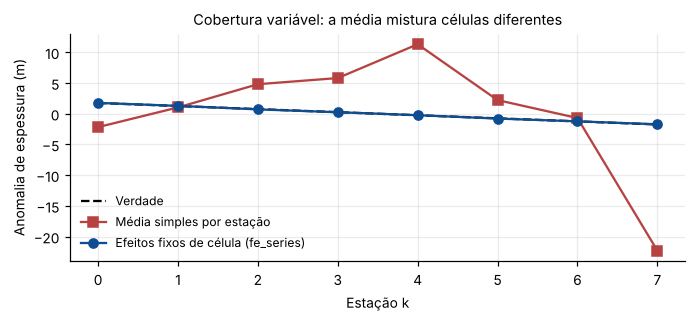

In [4]:
from thwaites.stats import fixed_effects_panel_series

rng = np.random.default_rng(7)
K, n_cel = 8, 80
s_verdadeira = -0.5 * np.arange(K)
pos = rng.choice(40 * 40, n_cel, replace=False)          # 80 células distintas numa grade de 20 × 20 km
cx, cy = (pos % 40 + 0.5) * 500.0, (pos // 40 + 0.5) * 500.0
base = rng.normal(300, 60, n_cel)
gx, gy = rng.normal(0, 0.03, n_cel), rng.normal(0, 0.03, n_cel)
px, py, Hs, ep = [], [], [], []
for c in range(n_cel):
    vistas = rng.random(K) < 0.5
    for k in np.flatnonzero(vistas):
        m = rng.integers(5, 20)
        ox, oy = rng.uniform(-240, 240, m), rng.uniform(-240, 240, m)
        px.append(cx[c] + ox); py.append(cy[c] + oy); ep.append(np.full(m, k))
        Hs.append(base[c] + gx[c] * ox + gy[c] * oy + s_verdadeira[k] + rng.normal(0, 0.5, m))
px, py, Hs, ep = map(np.concatenate, (px, py, Hs, ep))

s_fe, n_obs = fixed_effects_panel_series(px, py, Hs, ep, K, cell_size_m=500.0)
s_media = np.array([Hs[ep == k].mean() for k in range(K)]); s_media -= s_media.mean()
s_ref = s_verdadeira - s_verdadeira.mean()

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(range(K), s_ref, "k--", label="Verdade")
ax.plot(range(K), s_media, "s-", color="#B64342", label="Média simples por estação")
ax.plot(range(K), s_fe, "o-", color="#0F4D92", label="Efeitos fixos de célula (fe_series)")
ax.set_xlabel("Estação k"); ax.set_ylabel("Anomalia de espessura (m)")
ax.set_title("Cobertura variável: a média mistura células diferentes"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
pd.DataFrame({"RMSE vs. verdade (m)": [np.sqrt(np.mean((s_media - s_ref) ** 2)), np.sqrt(np.mean((s_fe - s_ref) ** 2))],
              "Tendência estimada (m/estação)": [np.polyfit(range(K), s_media, 1)[0], np.polyfit(range(K), s_fe, 1)[0]]},
             index=["Média simples", "Efeitos fixos"]).round(3)

**Leitura.** A média simples por estação mede, sobretudo, *quais* células foram vistas: uma célula de 400 m que entra numa estação e sai na seguinte produz saltos de dezenas de metros, sem qualquer relação com derretimento. O estimador *within* compara cada célula **consigo mesma** (elimina seu nível e seu plano local) e recupera a série verdadeira. No dado real, a cobertura orbital muda entre estações e entre anos, e esse é o viés de composição que o `fe_series` remove.

Com isso, as séries reais por plataforma e a escolha do interpolador de $DH/Dt$ ficam:

rmse_mpa                               dp_erro_padronizado                             
metodo        kernel_2km kernel_5km kernel_8km    krig          kernel_2km kernel_5km kernel_8km   krig
unidade                                                                                                
Cosgrove           3.874      3.855      3.844   3.853                 NaN        NaN        NaN  0.314
Crosson            7.428      8.868      9.834   7.087                 NaN        NaN        NaN  1.007
Dotson             7.049      8.784      9.668   5.503                 NaN        NaN        NaN  0.892
Pine_Island       15.379     18.754     22.518  13.315                 NaN        NaN        NaN  0.745
Thwaites_TEIS      8.156      8.922     10.194   8.026                 NaN        NaN        NaN  0.994
Thwaites_TWGT     26.444     28.213     31.184  26.149                 NaN        NaN        NaN  0.920

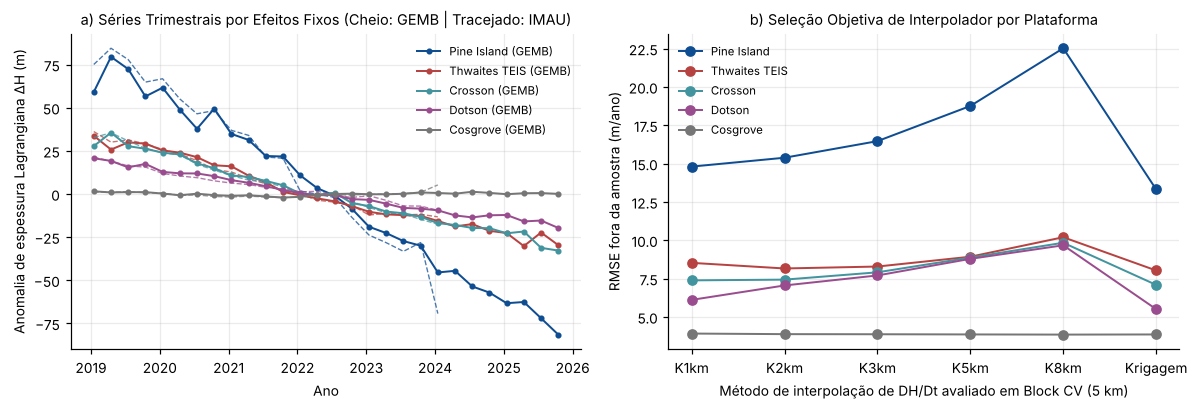

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.8))
colors = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E", "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
for u, col in colors.items():
    sub = ser_h[ser_h["plataforma"] == u].sort_values("t_meio")
    ax[0].plot(sub["t_meio"], sub["dH_lagr_m"], "o-", color=col, lw=1.3, ms=3, label=f"{u.replace('_', ' ')} (GEMB)")
    sub_im = sub[np.isfinite(sub["dH_lagr_imau_m"])]
    # As séries são anomalias (nível arbitrário): alinha a variante IMAU ao nível médio da GEMB no período comum
    imau_alinhada = sub_im["dH_lagr_imau_m"] - (sub_im["dH_lagr_imau_m"] - sub_im["dH_lagr_m"]).mean()
    ax[0].plot(sub_im["t_meio"], imau_alinhada, "--", color=col, lw=0.9, alpha=0.75)
ax[0].set_xlabel("Ano")
ax[0].set_ylabel("Anomalia de espessura Lagrangiana ΔH (m)")
ax[0].set_title("a) Séries Trimestrais por Efeitos Fixos (Cheio: GEMB | Tracejado: IMAU)")
ax[0].legend(frameon=False, fontsize=7.5)

piv_cv = cv_krig.pivot(index="unidade", columns="metodo", values="rmse_mpa")
for u, col in colors.items():
    if u in piv_cv.index:
        vals_u = piv_cv.loc[u, ["kernel_1km", "kernel_2km", "kernel_3km", "kernel_5km", "kernel_8km", "krig"]]
        ax[1].plot(["K1km", "K2km", "K3km", "K5km", "K8km", "Krigagem"], vals_u.to_numpy(dtype=float), "o-", color=col, lw=1.3, label=u.replace("_", " "))
ax[1].set_xlabel("Método de interpolação de DH/Dt avaliado em Block CV (5 km)")
ax[1].set_ylabel("RMSE fora da amostra (m/ano)")
ax[1].set_title("b) Seleção Objetiva de Interpolador por Plataforma")
ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

cv_krig[cv_krig["metodo"].isin(["kernel_2km", "kernel_5km", "kernel_8km", "krig"])].pivot(
    index="unidade", columns="metodo", values=["rmse_mpa", "dp_erro_padronizado"]
).round(3)

**Leitura da figura.**
- **(a)** As séries Lagrangianas por efeitos fixos mostram afinamento contínuo na PIG (~−24 m/ano de espessura), na TEIS, na Crosson (~−10 m/ano) e na Dotson (~−6 m/ano). A Cosgrove é praticamente estável. Sobre a tendência há oscilações sazonais de poucos metros. As variantes GEMB (cheio) e IMAU-FDM (tracejado, até 2023, alinhada ao nível da GEMB porque as séries são anomalias) têm a mesma forma, mas a inclinação difere ~4 m/ano na PIG. Essa diferença entre modelos de firn é uma das maiores fontes estruturais de incerteza ali (Seção 5).
- **(b)** A krigagem tem o menor RMSE em todas as plataformas, e o ganho é grande na Dotson e na PIG, onde o campo tem estrutura de canais. Entre os kernels, os mais largos pioram monotonicamente: suavizar mais apaga as feições reais. Na Cosgrove, de sinal quase uniforme, todos os métodos empatam.
- O erro padronizado da krigagem fica perto de 1 em Crosson, Dotson, TEIS e TWGT (variância de predição honesta) e abaixo de 1 na Cosgrove e na PIG (conservadora).

---

---
## 4. Investigação das Manchas de $m_b < 0$ (*Blue Spots*) e Comparação de Velocidade ITS_LIVE vs. MEaSUREs

Nos mapas de $500\text{ m}$, entre $2{,}3\%$ (Crosson) e $23{,}2\%$ (Cosgrove) dos pixels apresentam $m_b < 0$ aparente. Em vez de rotulá-los acriticamente como "recongelamento marinho basal (*marine ice accretion*)", testamos três hipóteses físicas (`run_blue_spots_ase.py` e `run_open_checks_ase.py`):
1. **Artefato de interpolação de $DH/Dt$?** **Descartado:** A fração de pixels negativos é praticamente idêntica nas células com observação direta do ICESat-2 e nas células interpoladas por krigagem (Dotson: $10{,}6\%$ observado vs. $8{,}7\%$ interpolado; Cosgrove: $21{,}7\%$ vs. $23{,}9\%$);
2. **Ruído de pequena escala na derivada de velocidade $\nabla\cdot\mathbf{u}$ e compensação hidrostática de fendas/canais (Chartrand et al., 2024)?** **Confirmado para a maior parte das manchas:** Ao aumentar a escala do filtro gaussiano de $\nabla\cdot\mathbf{u}$ de $1\text{ km}$ para $5\text{ km}$, a área negativa cai de $9{,}5\%$ para $0{,}96\%$ na Dotson e de $23{,}2\%$ para $6{,}5\%$ na Cosgrove, sem alterar a média da plataforma ($\le 0{,}1\text{ m/ano}$). Além disso, no produto de longo prazo de Paolo et al. (2023, 1992–2017) nos mesmos pixels, essas manchas não aparecem;
3. **Manchas persistentes nas 4 escalas:** Restam apenas duas feições que persistem de $1$ a $5\text{ km}$: a faixa sul da Cosgrove ($3\%$ da área com $m_b + 2\sigma < 0$) e um lobo de $\sim 41\text{ km}^2$ a oeste da Pine Island ($m_b \approx -5\text{ m/ano}$), onde há forte divergência extensional local.

,,frac_dominio,Hdiv_ITS_LIVE_mpa,Hdiv_MEaSUREs_mpa,diferenca_mpa,r_espacial
unidade,escala_km,,,,,
Pine_Island,2,1.0,6.403,5.924,-0.478,0.937
Thwaites_TEIS,2,1.0,2.234,1.734,-0.500,0.859
Crosson,2,1.0,0.975,0.865,-0.110,0.862
Dotson,2,1.0,-0.729,-0.696,0.033,0.824
Cosgrove,2,1.0,-0.158,-0.456,-0.298,0.557
Pine_Island,3,1.0,6.483,5.874,-0.609,0.938
Thwaites_TEIS,3,1.0,2.868,1.876,-0.993,0.748
Crosson,3,1.0,0.978,0.897,-0.081,0.918
Dotson,3,1.0,-0.765,-0.740,0.025,0.876


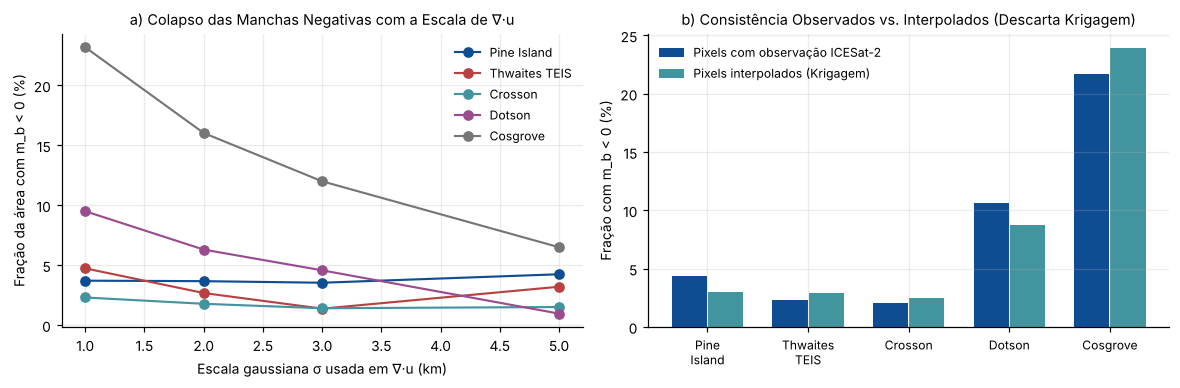

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
scales_cols = ["frac_neg_div1km", "frac_neg_div2km", "frac_neg_div3km", "frac_neg_div5km"]
for _, row in blue_spots.iterrows():
    u = row["unidade"]
    if u in colors:
        ax[0].plot([1, 2, 3, 5], [100 * row[c] for c in scales_cols], "o-", color=colors[u], lw=1.4, label=u.replace("_", " "))
ax[0].set_xlabel("Escala gaussiana σ usada em ∇·u (km)")
ax[0].set_ylabel("Fração da área com m_b < 0 (%)")
ax[0].set_title("a) Colapso das Manchas Negativas com a Escala de ∇·u")
ax[0].legend(frameon=False, fontsize=8)

x_u = np.arange(len(blue_spots))
ax[1].bar(x_u - 0.18, 100 * blue_spots["frac_neg_em_pix_observados"], width=0.35, color="#0F4D92", label="Pixels com observação ICESat-2")
ax[1].bar(x_u + 0.18, 100 * blue_spots["frac_neg_em_pix_interpolados"], width=0.35, color="#42949E", label="Pixels interpolados (Krigagem)")
ax[1].set_xticks(x_u)
ax[1].set_xticklabels([u.replace("_", "\n") for u in blue_spots["unidade"]], fontsize=8)
ax[1].set_ylabel("Fração com m_b < 0 (%)")
ax[1].set_title("b) Consistência Observados vs. Interpolados (Descarta Krigagem)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

vel_check.set_index(["unidade", "escala_km"]).round(3)

**Leitura do resultado.**
- **(a)** Ao suavizar $\nabla\cdot\mathbf{u}$ de 1 para 5 km, a área negativa cai fortemente em Dotson e Cosgrove, sem mudar a média da plataforma. As manchas são, em grande parte, ruído de derivada amplificado por $H$, não recongelamento.
- **(b)** A fração negativa é igual em pixels observados e interpolados, então a krigagem não as cria.
- **Velocidade:** ITS_LIVE e MEaSUREs dão $H\nabla\cdot\mathbf{u}$ muito correlacionados ($r = 0{,}6$–$0{,}94$) e diferenças médias abaixo de 1 m/ano, exceto na TEIS em escalas grandes (−1,7 m/ano a 5 km), onde a margem de cisalhamento muda rapidamente entre as épocas dos dois mosaicos. Essa diferença entra no orçamento como `fator_velocidade`.

A tabela abaixo testa diretamente a hipótese de recongelamento: quanta área tem $m_b + 2\sigma < 0$ (negativo **significativo**)?

In [7]:
check_refreeze.set_index("unidade").rename(columns={
    "frac_mb_negativo": "Fração com m_b < 0", "frac_recongelamento_signif": "Fração com m_b + 2σ < 0",
    "n_manchas_signif": "Nº de manchas significativas", "maior_mancha_km2": "Maior mancha (km²)",
    "manchas_ge_5km2": "Manchas ≥ 5 km²"}).round(4)

,Fração com m_b < 0,Fração com m_b + 2σ < 0,Nº de manchas significativas,Maior mancha (km²),Manchas ≥ 5 km²
unidade,,,,,
Pine_Island,0.0255,0.0014,1,5.25,1
Thwaites_TEIS,0.0338,0.0000,0,0.00,0
Crosson,0.0179,0.0000,0,0.00,0
Dotson,0.1040,0.0031,3,11.00,1
Cosgrove,0.2232,0.0278,22,22.00,2


**Leitura.** Na PIG, TEIS, Crosson e Dotson, menos de 0,3% da área tem derretimento negativo significativo, com no máximo uma ou duas manchas ≥ 5 km². Só a Cosgrove (2,8%, faixa sul) tem um sinal persistente que merece investigação com dados independentes. A conclusão é conservadora: **o produto não sustenta recongelamento basal extenso na ASE**.

---
## 5. Incerteza Estrutural Fatorial e Comparação com a Literatura

**Fundamentação.** Em vez de uma única versão do mapa, o pipeline varre em **projeto fatorial completo** todas as escolhas metodológicas defensáveis (máscara, recorte da frente, limiar de perda, distância à observação, tolerância do radar, escala de $\nabla\cdot\mathbf{u}$, SMB, firn e, na TEIS, a recuperação da zona de aterramento), com 5.184 a 6.912 combinações por plataforma. O efeito de cada fator é a variação da média de $m_b$ quando só ele muda. A agregação (média por pixel × por série) e a velocidade são avaliadas à parte.

,sigma_estat,sigma_estrutural,sigma_total,fator_dominante,n_comb
unidade,,,,,
Pine_Island,0.475,4.510,4.535,agregacao,5184
Thwaites_TEIS,0.401,3.075,3.101,agregacao,6912
Crosson,0.247,1.190,1.216,agregacao,5184
Dotson,0.168,0.740,0.759,fatorial,5184
Cosgrove,0.086,0.374,0.384,velocidade,5184


,este_trabalho,sigma_estat,sigma_total,meng,meng_sigma,paolo_1992_2017_mesmos_pixels,Diferença vs. Meng (m/ano),z vs. Meng
unidade,,,,,,,,
Pine_Island,17.53,0.48,4.53,16.28,1.46,18.89,1.25,0.26
Thwaites_TEIS,6.88,0.40,3.10,7.13,1.25,5.85,-0.25,-0.07
Crosson,8.76,0.25,1.22,7.79,1.65,11.00,0.97,0.47
Dotson,6.66,0.17,0.76,7.15,1.45,6.66,-0.49,-0.30
Cosgrove,0.71,0.09,0.38,1.22,1.02,1.40,-0.51,-0.47


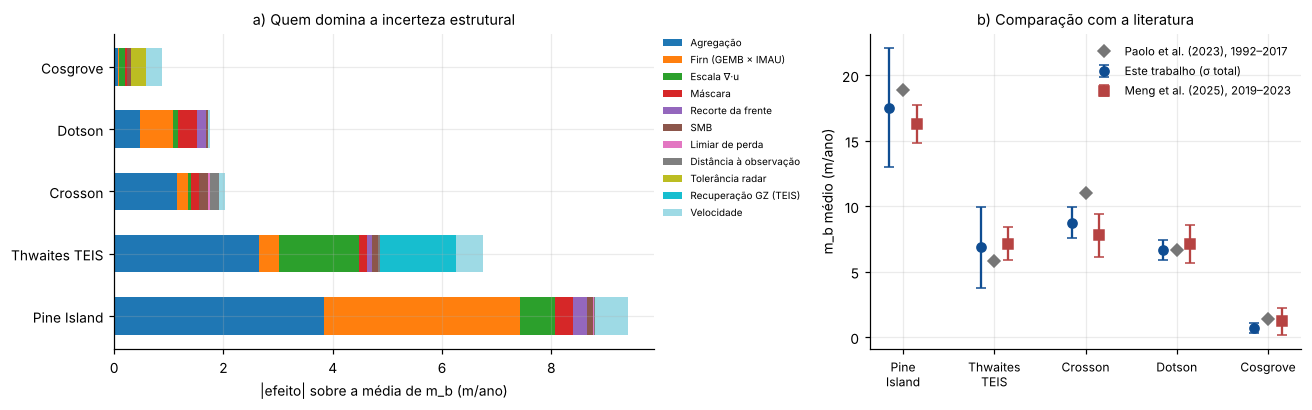

In [8]:
fatores = ["agregacao", "efeito_firn", "efeito_escala_km", "efeito_mascara", "efeito_frente_km", "efeito_smb",
           "efeito_perda_max", "efeito_obs_km", "efeito_radar_tol", "efeito_thwaites", "velocidade"]
nomes = {"agregacao": "Agregação", "efeito_firn": "Firn (GEMB × IMAU)", "efeito_escala_km": "Escala ∇·u",
         "efeito_mascara": "Máscara", "efeito_frente_km": "Recorte da frente", "efeito_smb": "SMB",
         "efeito_perda_max": "Limiar de perda", "efeito_obs_km": "Distância à observação",
         "efeito_radar_tol": "Tolerância radar", "efeito_thwaites": "Recuperação GZ (TEIS)", "velocidade": "Velocidade"}
efe = unc_v2.set_index("unidade")[fatores].abs().fillna(0.0).rename(columns=nomes)
comp = pd.read_csv(DATA_DIR / "comparacao_meng2025_paolo2023.csv").set_index("unidade")

fig, ax = plt.subplots(1, 2, figsize=(12.0, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
base_acum = np.zeros(len(efe))
paleta = plt.cm.tab20(np.linspace(0, 1, len(efe.columns)))
for j, col in enumerate(efe.columns):
    ax[0].barh(efe.index.str.replace("_", " "), efe[col], left=base_acum, color=paleta[j], label=col, height=0.6)
    base_acum += efe[col].to_numpy()
ax[0].set_xlabel("|efeito| sobre a média de m_b (m/ano)"); ax[0].set_title("a) Quem domina a incerteza estrutural")
ax[0].legend(frameon=False, fontsize=6.5, ncol=1, loc="upper left", bbox_to_anchor=(1.0, 1.02))

xu = np.arange(len(comp))
ax[1].errorbar(xu - 0.15, comp["este_trabalho"], yerr=comp["sigma_total"], fmt="o", color="#0F4D92", capsize=3, label="Este trabalho (σ total)")
ax[1].errorbar(xu + 0.15, comp["meng"], yerr=comp["meng_sigma"], fmt="s", color="#B64342", capsize=3, label="Meng et al. (2025), 2019–2023")
ax[1].plot(xu, comp["paolo_1992_2017_mesmos_pixels"], "D", color="#767676", label="Paolo et al. (2023), 1992–2017")
ax[1].set_xticks(xu); ax[1].set_xticklabels(comp.index.str.replace("_", "\n"), fontsize=8)
ax[1].set_ylabel("m_b médio (m/ano)"); ax[1].set_title("b) Comparação com a literatura"); ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

comp = comp.assign(**{"Diferença vs. Meng (m/ano)": comp["este_trabalho"] - comp["meng"],
                      "z vs. Meng": (comp["este_trabalho"] - comp["meng"]) / np.hypot(comp["sigma_total"], comp["meng_sigma"])})
display(unc_v2.set_index("unidade")[["sigma_estat", "sigma_estrutural", "sigma_total", "fator_dominante", "n_comb"]].round(3))
comp.round(2)

**Leitura do resultado.**
- **(a)** A **agregação** (como se passa de células observadas para a média da plataforma) é o fator dominante em todas as plataformas. Na PIG, o modelo de **firn** pesa quase o mesmo (~3,6 m/ano). Na TEIS, a escala de $\nabla\cdot\mathbf{u}$ e a recuperação da zona de aterramento também importam. Máscara, frente, SMB e limiares contribuem com décimos de m/ano.
- **(b)** Todas as plataformas concordam com Meng et al. (2025) dentro de $|z| < 1$, com incertezas totais honestas: as nossas são maiores que as declaradas por Meng porque incluem firn, agregação e velocidade. A Crosson derreteu menos em 2019–2025 do que em 1992–2017 (Paolo et al., 2023), coerente com a desaceleração do afinamento relatada nesse trabalho. Nas demais, a média de longo prazo está dentro da faixa atual.

---
## 6. Síntese do Caderno

| Pergunta | Resposta | Evidência |
|---|---|---|
| Quanto derretem as plataformas da ASE? | PIG 17,5 ± 4,5; Crosson 8,8 ± 1,2; TEIS 6,9 ± 3,1; Dotson 6,7 ± 0,8; Cosgrove 0,7 ± 0,4 m/ano | tabela final (§1) |
| Massa total | ~94 ± 20 Gt/ano na área medida; 152–165 Gt/ano extrapolado para as plataformas inteiras | §1 |
| Como derivar $\nabla\cdot\mathbf{u}$? | convolução gaussiana normalizada, $\sigma^*$ por CV anos pares × ímpares (1–3 km) | §2 |
| Como construir $DH/Dt$? | efeitos fixos de célula material, imunes à mudança de cobertura | §3 |
| Há recongelamento? | não extenso: < 0,3% significativo, exceto faixa sul da Cosgrove | §4 |
| Qual a incerteza dominante? | estrutural (agregação, firn), 5–10× a estatística | §5 |
| Concorda com a literatura? | sim, $\lvert z\rvert < 1$ vs. Meng et al. (2025) em todas | §5 |

**Scripts do pipeline:** `pipelines/derretimento_basal/run_basal_ase_all.py` (cadeia completa), `run_thickness_ase.py`, `run_divergence_ase.py`, `run_blue_spots_ase.py`, `run_open_checks_ase.py`, `run_factorial_v2_ase.py`.

**Próximo caderno:** o Caderno 07 valida a espessura hidrostática com radar aerotransportado e o derretimento com radares de fase ApRES *in situ*.